In [2]:
import os
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from dotenv import load_dotenv
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
from scipy.stats import mannwhitneyu

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.3f}".format)

# Visualisation settings
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Load database credentials from the .env file
load_dotenv()

# Check that all required variables are available
required_variables = [
    "DB_USER",
    "DB_PASSWORD",
    "DB_HOST",
    "DB_PORT",
    "DB_NAME"
]

missing_variables = [
    variable for variable in required_variables
    if not os.getenv(variable)
]

if missing_variables:
    raise ValueError(
        f"Missing environment variables: {missing_variables}"
    )

# Database schema
schema = os.getenv("DB_SCHEMA", "s_atikesanli")

# Validate schema name
if not re.fullmatch(r"[A-Za-z_][A-Za-z0-9_]*", schema):
    raise ValueError("Invalid database schema name.")

# Create database connection
connection_url = URL.create(
    drivername="postgresql+psycopg",
    username=os.getenv("DB_USER"),
    password=os.getenv("DB_PASSWORD"),
    host=os.getenv("DB_HOST"),
    port=int(os.getenv("DB_PORT")),
    database=os.getenv("DB_NAME")
)

engine = create_engine(
    connection_url,
    connect_args={
        "options": "-c default_transaction_read_only=on"
    }
)

# Test connection
with engine.connect() as connection:
    database_info = connection.execute(
        text("""
            SELECT
                current_database() AS database_name,
                current_user AS database_user,
                version() AS postgresql_version
        """)
    ).fetchone()

print("PostgreSQL connection successful!")
print("Database:", database_info.database_name)
print("User:", database_info.database_user)
print("Schema:", schema)
print("Version:", database_info.postgresql_version)

PostgreSQL connection successful!
Database: nf_da_onl_en_200726
User: atikesanli
Schema: s_atikesanli
Version: PostgreSQL 17.9 on x86_64-pc-linux-gnu, compiled by x86_64-pc-linux-gnu-gcc (GCC) 12.4.0, 64-bit


In [4]:
rq5_tables_query = text("""
    SELECT
        table_name,
        table_type
    FROM information_schema.tables
    WHERE table_schema = :schema_name
      AND (
          table_name ILIKE '%lead%'
          OR table_name ILIKE '%market%'
          OR table_name ILIKE '%seller%'
      )
    ORDER BY table_name
""")

with engine.connect() as connection:
    rq5_tables = pd.read_sql_query(
        rq5_tables_query,
        connection,
        params={"schema_name": schema}
    )

display(rq5_tables)

,table_name,table_type
0,mart_acquired_seller_performance,VIEW
1,olist_sellers,BASE TABLE


In [5]:
all_tables_query = text("""
    SELECT
        table_name,
        table_type
    FROM information_schema.tables
    WHERE table_schema = :schema_name
    ORDER BY table_name
""")

with engine.connect() as connection:
    all_tables = pd.read_sql_query(
        all_tables_query,
        connection,
        params={"schema_name": schema}
    )

display(all_tables)

,table_name,table_type
0,countries,BASE TABLE
1,countries_selection,BASE TABLE
2,customer_clean,BASE TABLE
3,customers,BASE TABLE
4,daily_city_stats,VIEW
5,exam_scores,BASE TABLE
6,ilayda_authors,BASE TABLE
7,ilayda_books,BASE TABLE
8,ilayda_customers,BASE TABLE
9,ilayda_orders,BASE TABLE


In [6]:
rq5_columns_query = text("""
    SELECT
        table_name,
        column_name,
        data_type
    FROM information_schema.columns
    WHERE table_schema = :schema_name
      AND table_name IN (
          'olist_mql',
          'olist_closed_deals'
      )
    ORDER BY table_name, ordinal_position
""")

with engine.connect() as connection:
    rq5_columns = pd.read_sql_query(
        rq5_columns_query,
        connection,
        params={"schema_name": schema}
    )

display(rq5_columns)

,table_name,column_name,data_type
0,olist_closed_deals,mql_id,character varying
1,olist_closed_deals,seller_id,character varying
2,olist_closed_deals,sdr_id,character varying
3,olist_closed_deals,sr_id,character varying
4,olist_closed_deals,won_date,timestamp without time zone
5,olist_closed_deals,business_segment,text
6,olist_closed_deals,lead_type,text
7,olist_closed_deals,lead_behaviour_profile,text
8,olist_closed_deals,has_company,boolean
9,olist_closed_deals,has_gtin,boolean


In [7]:
rq5_query = text(f"""
    SELECT
        m.mql_id,
        m.first_contact_date,
        m.origin,
        CASE
            WHEN d.mql_id IS NOT NULL THEN 1
            ELSE 0
        END AS converted,
        d.won_date,
        d.seller_id
    FROM {schema}.olist_mql AS m
    LEFT JOIN {schema}.olist_closed_deals AS d
        ON m.mql_id = d.mql_id
""")

with engine.connect() as connection:
    rq5_df = pd.read_sql_query(rq5_query, connection)

print("Dataset shape:", rq5_df.shape)
display(rq5_df.head(10))

Dataset shape: (8000, 6)


,mql_id,first_contact_date,origin,converted,won_date,seller_id
0,dac32acd4db4c29c230538b72f8dd87d,2018-02-01,social,0,NaT,NaN
1,8c18d1de7f67e60dbd64e3c07d7e9d5d,2017-10-20,paid_search,0,NaT,NaN
2,b4bc852d233dfefc5131f593b538befa,2018-03-22,organic_search,0,NaT,NaN
3,6be030b81c75970747525b843c1ef4f8,2018-01-22,email,0,NaT,NaN
4,5420aad7fec3549a85876ba1c529bd84,2018-02-21,organic_search,1,2018-02-26 19:58:54,2c43fb513632d29b3b58df74816f1b06
5,28bdfd5f057764b54c38770f95c69f2f,2018-01-14,organic_search,0,NaT,NaN
6,126a0d10becbaafcb2e72ce6848cf32c,2018-05-15,email,0,NaT,NaN
7,f76136f54d14a3345951f25b7932366b,2018-05-24,email,0,NaT,NaN
8,2f838cade4a6012a6cb1016d1d8d95ed,2017-11-10,organic_search,0,NaT,NaN
9,7281942387a1a0c3f72a50a8b0bb0920,2017-12-25,social,0,NaT,NaN


In [8]:
duplicate_check_query = text(f"""
    SELECT
        'olist_mql' AS source_table,
        COUNT(*) AS total_rows,
        COUNT(DISTINCT mql_id) AS unique_mql_ids
    FROM {schema}.olist_mql

    UNION ALL

    SELECT
        'olist_closed_deals' AS source_table,
        COUNT(*) AS total_rows,
        COUNT(DISTINCT mql_id) AS unique_mql_ids
    FROM {schema}.olist_closed_deals
""")

with engine.connect() as connection:
    duplicate_check = pd.read_sql_query(
        duplicate_check_query, connection
    )

display(duplicate_check)

,source_table,total_rows,unique_mql_ids
0,olist_mql,8000,8000
1,olist_closed_deals,842,842


In [9]:
origin_summary = (
    rq5_df.groupby("origin", dropna=False)
    .agg(
        total_leads=("mql_id", "nunique"),
        converted_leads=("converted", "sum")
    )
    .reset_index()
)

origin_summary["not_converted"] = (
    origin_summary["total_leads"]
    - origin_summary["converted_leads"]
)

origin_summary["conversion_rate"] = (
    origin_summary["converted_leads"]
    / origin_summary["total_leads"] * 100
)

origin_summary = origin_summary.sort_values(
    "conversion_rate", ascending=False
)

display(origin_summary.round(2))

,origin,total_leads,converted_leads,not_converted,conversion_rate
9,unknown,1159,193,966,16.650
6,paid_search,1586,195,1391,12.300
3,organic_search,2296,271,2025,11.800
0,direct_traffic,499,56,443,11.220
7,referral,284,24,260,8.450
8,social,1350,75,1275,5.560
1,display,118,6,112,5.080
5,other_publicities,65,3,62,4.620
2,email,493,15,478,3.040
4,other,150,4,146,2.670


In [10]:
from scipy.stats import chi2_contingency
import numpy as np

# Create contingency table
origin_conversion_table = pd.crosstab(
    rq5_df["origin"],
    rq5_df["converted"]
)

# Run chi-square test
chi2, p_value, degrees_of_freedom, expected = chi2_contingency(
    origin_conversion_table
)

# Calculate Cramér's V (effect size)
n = origin_conversion_table.to_numpy().sum()
minimum_dimension = min(origin_conversion_table.shape) - 1

cramers_v = np.sqrt(
    chi2 / (n * minimum_dimension)
)

print(f"Chi-square statistic: {chi2:.3f}")
print(f"Degrees of freedom: {degrees_of_freedom}")
print(f"P-value: {p_value:.6f}")
print(f"Cramér's V: {cramers_v:.4f}")
print(f"Minimum expected cell frequency: {expected.min():.2f}")

print("\nExpected frequencies:")
display(pd.DataFrame(
    expected,
    index=origin_conversion_table.index,
    columns=["Not converted", "Converted"]
).round(2))

Chi-square statistic: 137.687
Degrees of freedom: 9
P-value: 0.000000
Cramér's V: 0.1312
Minimum expected cell frequency: 6.84

Expected frequencies:


,Not converted,Converted
origin,,
direct_traffic,446.480,52.520
display,105.580,12.420
email,441.110,51.890
organic_search,2054.350,241.650
other,134.210,15.790
other_publicities,58.160,6.840
paid_search,1419.070,166.930
referral,254.110,29.890
social,1207.910,142.090


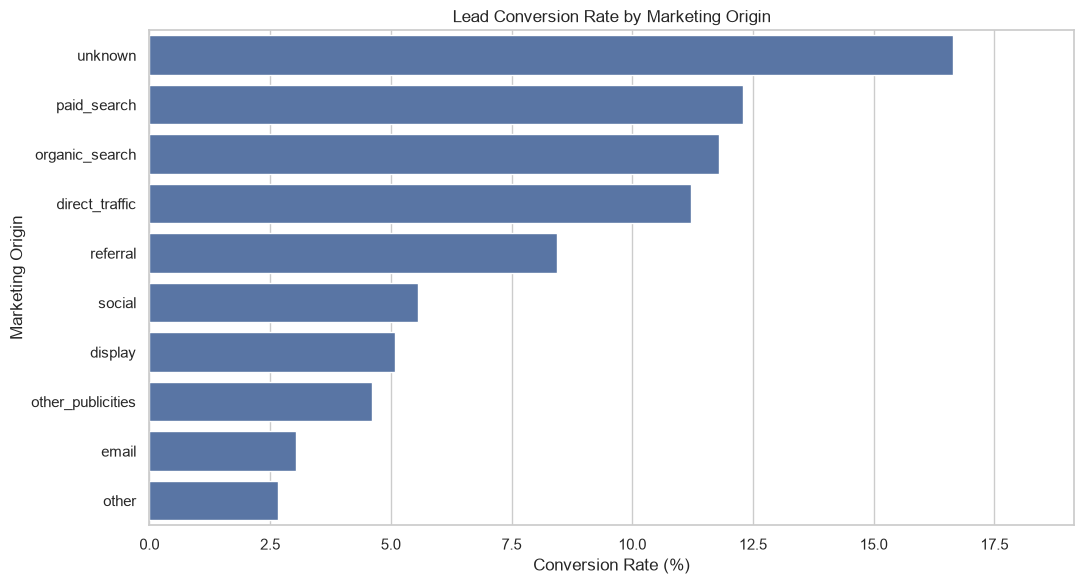

In [12]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=origin_summary,
    x="conversion_rate",
    y="origin"
)

plt.title("Lead Conversion Rate by Marketing Origin")
plt.xlabel("Conversion Rate (%)")
plt.ylabel("Marketing Origin")
plt.xlim(0, origin_summary["conversion_rate"].max() * 1.15)

plt.tight_layout()
plt.savefig(
    "../figures/rq5_conversion_rate_by_origin.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

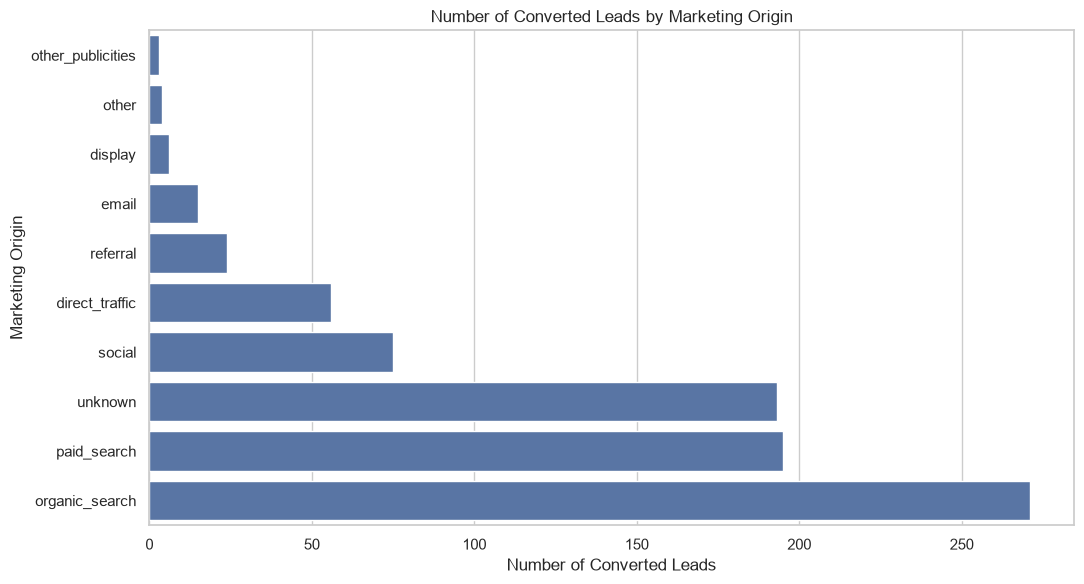

In [14]:
plt.figure(figsize=(11, 6))

volume_df = origin_summary.sort_values(
    "converted_leads", ascending=True
)

sns.barplot(
    data=volume_df,
    x="converted_leads",
    y="origin"
)

plt.title("Number of Converted Leads by Marketing Origin")
plt.xlabel("Number of Converted Leads")
plt.ylabel("Marketing Origin")

plt.tight_layout()
plt.savefig(
    "../figures/rq5_converted_leads_by_origin.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### RQ5: Marketing Funnel Conversion Performance

The fifth research question investigated how effectively the Olist marketing funnel converts qualified leads into acquired sellers and whether conversion performance varies according to lead origin.

The analysis included 8,000 marketing qualified leads, of which 842 were successfully converted into acquired sellers, resulting in an overall conversion rate of 10.53%. The remaining 7,158 leads (89.47%) did not have a corresponding closed-deal record.

Conversion performance varied across marketing origins. Leads with an unknown origin recorded the highest conversion rate at 16.65%. Among identifiable marketing channels, paid search achieved the highest conversion rate (12.30%), followed by organic search (11.80%) and direct traffic (11.22%). Organic search generated the largest absolute number of acquired sellers, with 271 conversions, followed by paid search with 195 conversions. In contrast, email (3.04%) and other sources (2.67%) recorded the lowest conversion rates.

To examine whether these differences were statistically significant, a chi-square test of independence was conducted. The results revealed a statistically significant association between marketing origin and conversion status (χ²(9) = 137.687, p < .001). The minimum expected cell frequency was 6.84, satisfying the expected-frequency assumption of the test. Cramér's V was 0.1312, indicating a relatively weak association.

Consequently, the null hypothesis was rejected, suggesting that lead origin and conversion status are not independent. Nevertheless, the relatively small effect size indicates that marketing origin alone has limited explanatory power in relation to lead conversion.

Overall, the findings demonstrate that marketing origin is associated with the effectiveness of the Olist lead conversion process. Organic search was the largest contributor to acquired sellers in terms of conversion volume, while paid search achieved the highest conversion rate among identifiable channels. These findings suggest that marketing performance should be evaluated using both conversion rates and the absolute number of acquired sellers. However, the results indicate an association rather than a causal relationship, and other lead characteristics and business factors may also influence conversion outcomes.